In [7]:

import pandas as pd

dados = {
    "id_solicitacao": list(range(1, 16)),
    "idade": [22, 25, 34, 41, 28, 52, 37, 24, 46, 33, 29, 55, 39, 26, 48],
    "motivo_negativa": [
        "Renda insuficiente",
        "Motivo não informado",
        "Documentação incompleta",
        "Renda insuficiente",
        "Motivo não informado",
        "Critérios não atendidos",
        "Documentação incompleta",
        "Renda insuficiente",
        "Motivo não informado",
        "Critérios não atendidos",
        "Renda insuficiente",
        "Documentação incompleta",
        "Motivo não informado",
        "Critérios não atendidos",
        "Renda insuficiente"
    ],
    "motivo_informado": [
        "Sim", "Não", "Sim", "Sim", "Não",
        "Sim", "Sim", "Sim", "Não", "Sim",
        "Sim", "Sim", "Não", "Sim", "Sim"
    ],
    "orientacao_proximo_passo": [
        "Sim", "Não", "Sim", "Não", "Não",
        "Sim", "Não", "Sim", "Não", "Sim",
        "Não", "Sim", "Não", "Sim", "Não"
    ]
}

df = pd.DataFrame(dados)

df


,id_solicitacao,idade,motivo_negativa,motivo_informado,orientacao_proximo_passo
0,1,22,Renda insuficiente,Sim,Sim
1,2,25,Motivo não informado,Não,Não
2,3,34,Documentação incompleta,Sim,Sim
3,4,41,Renda insuficiente,Sim,Não
4,5,28,Motivo não informado,Não,Não
5,6,52,Critérios não atendidos,Sim,Sim
6,7,37,Documentação incompleta,Sim,Não
7,8,24,Renda insuficiente,Sim,Sim
8,9,46,Motivo não informado,Não,Não
9,10,33,Critérios não atendidos,Sim,Sim


In [8]:
# Contar os registros por resposta
df["motivo_informado"].value_counts()

,count
motivo_informado,
Sim,11
Não,4


In [10]:
(df["motivo_informado"] == "Não").mean() * 100

np.float64(26.666666666666668)

In [11]:
df["faixa_etaria"] = pd.cut(
    df["idade"],
    bins=[0, 29, 44, 100],
    labels=["18-29", "30-44", "45+"]
)

df.groupby("faixa_etaria", observed=True)["motivo_informado"].apply(
    lambda x: (x == "Não").mean() * 100
).round(1)

,motivo_informado
faixa_etaria,
18-29,33.3
30-44,20.0
45+,25.0


/tmp/ipykernel_718/1993144646.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby("faixa_etaria")["motivo_informado"].apply(


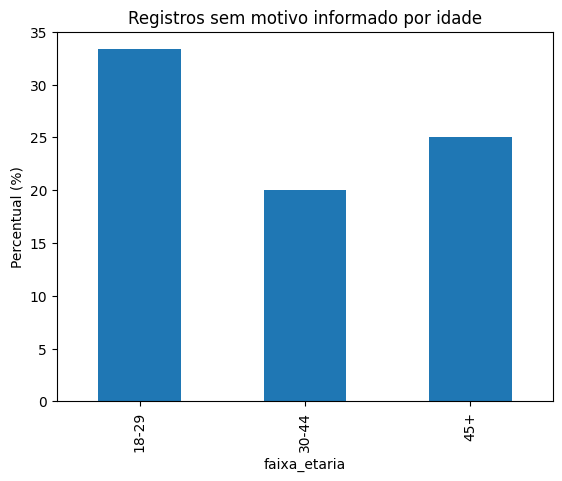

In [12]:
df.groupby("faixa_etaria")["motivo_informado"].apply(
    lambda x: (x == "Não").mean() * 100
).plot(kind="bar")

plt.title("Registros sem motivo informado por idade")
plt.ylabel("Percentual (%)")
plt.show()

## Proposta de melhoria

Uma possível melhoria seria tornar as mensagens de negativa mais claras para o cliente, explicando o motivo de forma simples e indicando os próximos passos, quando aplicável.

A proposta é avaliar o uso de mensagens padronizadas para reduzir dúvidas e facilitar a compreensão do cliente.

Essa melhoria precisaria ser validada com as áreas responsáveis.

## Conclusão

Neste projeto, utilizei Python e Pandas para analisar uma base fictícia com 15 solicitações financeiras. Analisei os registros de motivos informados e comparei os percentuais por faixa etária, utilizando gráficos para visualizar os resultados.

Na base simulada, a faixa de 18 a 29 anos apresentou o maior percentual de registros sem motivo informado, com 33,3%.

Como os dados são fictícios e a amostra é pequena, os resultados não representam necessariamente os clientes reais. O próximo passo seria validar a disponibilidade de dados autorizados para aprofundar a análise.